# Phase 5 — Explainable Fuzzy Classifier

**Objective:** Classify seven facial expressions from KDEF using 3–10 interpretable geometric features and a fuzzy inference system.

**Experimental protocol:**
- Original KDEF photographs, frontal pose only.
- Subject-independent 80/20 train/test split.
- Predefined subject assignments from `auxFiles/kdef_subject_split.pkl`.
- dlib 68-point facial landmarks.
- Separate `emotion_fuzzy` Conda environment.

## 1. Environment and dataset configuration

Resolve local data paths and load the team's predefined subject split.

In [11]:
from pathlib import Path
import os
import pickle

import numpy as np
import pandas as pd
import cv2
import dlib

# Locate the repository regardless of the notebook working directory.
cwd = Path.cwd().resolve()
ROOT = next(
    (p for p in (cwd, *cwd.parents)
     if (p / "auxFiles/kdef_subject_split.pkl").is_file()),
    None
)
if ROOT is None:
    raise FileNotFoundError("Repository root not found")

# Local paths; KDEF_ROOT can be overridden for other team members.
KDEF_ROOT = Path(
    os.getenv("KDEF_ROOT", str(ROOT.parent / "KDEF"))
).expanduser().resolve()

SPLIT_FILE = ROOT / "auxFiles/kdef_subject_split.pkl"
PREDICTOR_FILE = ROOT / "models/faceAndLandmarkModels/shape_predictor_68_face_landmarks.dat"
DATA_OUT = ROOT / "data/fuzzy"
OUT = ROOT / "outputs/fuzzy"

for path in (KDEF_ROOT, SPLIT_FILE, PREDICTOR_FILE):
    if not path.exists():
        raise FileNotFoundError(path)

for path in (DATA_OUT, OUT):
    path.mkdir(parents=True, exist_ok=True)

# Reuse the team's predefined subject-independent partition.
with SPLIT_FILE.open("rb") as f:
    split = pickle.load(f)

train_subjects = set(split["train_subjects"])
test_subjects = set(split["test_subjects"])

assert train_subjects.isdisjoint(test_subjects), "Subject leakage detected"
assert (len(train_subjects), len(test_subjects)) == (56, 14)

print(f"KDEF: {KDEF_ROOT}")
print(f"Split: {len(train_subjects)} train / {len(test_subjects)} test subjects")
print(f"NumPy: {np.__version__} | dlib: {dlib.__version__}")

KDEF: /Users/henriquedasilvacouto/workspace/TUe-Master_AI_and_ES/Masters-database/5ARE0_2026-GS1/Assignment_2/KDEF
Split: 56 train / 14 test subjects
NumPy: 1.24.4 | dlib: 19.24.2


## 2. KDEF metadata — Frontal images

Parse the original KDEF filenames into subject identity,
acquisition session, emotion, pose, and image path.

Both acquisition sessions belong to the same subject.
The filename corrections follow the team's existing KDEF loader.

In [12]:
EMOTIONS = {
    "AF": "afraid",
    "AN": "angry",
    "DI": "disgust",
    "HA": "happy",
    "NE": "neutral",
    "SA": "sad",
    "SU": "surprise",
}
OVERRIDES = {"AF31V": "AF31SAHL", "AM31H": "AM31SUHR"}
VALID_POSES = {"FL", "HL", "S", "HR", "FR"}

rows = []
rejected = []
for path in sorted(KDEF_ROOT.rglob("*")):
    if not path.is_file() or path.suffix.lower() not in (".jpg", ".jpeg"):
        continue

    stem = OVERRIDES.get(path.stem.upper(), path.stem.upper())
    if len(stem) < 7:
        rejected.append((str(path), "short filename"))
        continue

    emotion_code = stem[4:6]
    pose_code = stem[6:]
    if emotion_code not in EMOTIONS or pose_code not in VALID_POSES:
        rejected.append((str(path), f"unrecognized emotion/pose: {stem}"))
        continue
    if pose_code != "S":
        continue

    rows.append({
        "path": str(path),
        "image_name": path.name,
        "subject": stem[1:4],
        "acquisition": stem[0],
        "emotion": EMOTIONS[emotion_code],
        "pose": "straight",
    })

meta = pd.DataFrame(rows)
assert len(meta) == 980
assert meta["subject"].nunique() == 70
assert meta["emotion"].value_counts().eq(140).all()

print(f"Loaded {len(meta)} frontal images from {meta['subject'].nunique()} subjects")
print(meta["emotion"].value_counts().sort_index())
if rejected:
    print(f"Unrecognized filenames: {len(rejected)}")
    print(rejected[:5])

meta.head()

Loaded 980 frontal images from 70 subjects
afraid      140
angry       140
disgust     140
happy       140
neutral     140
sad         140
surprise    140
Name: emotion, dtype: int64


,path,image_name,subject,acquisition,emotion,pose
0,/Users/henriquedasilvacouto/workspace/TUe-Mast...,AF01AFS.JPG,F01,A,afraid,straight
1,/Users/henriquedasilvacouto/workspace/TUe-Mast...,AF01ANS.JPG,F01,A,angry,straight
2,/Users/henriquedasilvacouto/workspace/TUe-Mast...,AF01DIS.JPG,F01,A,disgust,straight
3,/Users/henriquedasilvacouto/workspace/TUe-Mast...,AF01HAS.JPG,F01,A,happy,straight
4,/Users/henriquedasilvacouto/workspace/TUe-Mast...,AF01NES.JPG,F01,A,neutral,straight


## 3. Apply the predefined subject split

Assign each frontal image to the training or test group using the subject IDs loaded earlier. Both photographic sessions of a person must remain in the same group.

In [13]:
# The subject groups were loaded in Section 1.
if not meta["subject"].isin(train_subjects | test_subjects).all():
    raise ValueError("Some KDEF subjects are missing from the predefined split")

meta["split"] = np.where(meta["subject"].isin(train_subjects), "train", "test")
print(meta.groupby(["split", "emotion"]).size().unstack(fill_value=0))
print(meta.groupby("split")["subject"].nunique())

emotion  afraid  angry  disgust  happy  neutral  sad  surprise
split                                                         
test         28     28       28     28       28   28        28
train       112    112      112    112      112  112       112
split
test     14
train    56
Name: subject, dtype: int64


## 4. Define the geometric features

Use the dlib 68-point landmarks to calculate seven simple measurements of the eyes, eyebrows, and mouth. Most distances are normalized to reduce the effect of face size. The mouth width-to-height ratio describes mouth shape rather than directly measuring happiness.

In [14]:
from numpy.linalg import norm

FEATURE_COLS = [
    "mouth_width",
    "mouth_opening",
    "left_eye_opening",
    "right_eye_opening",
    "eyebrow_height",
    "smile_ratio",
    "mouth_corner_asymmetry",
]


def landmark_distance(points, index_a, index_b):
    """Calculate the Euclidean distance between two facial landmarks."""
    return float(norm(points[index_a] - points[index_b]))


def geometric_features(points):
    """Extract seven ratios from the 68 facial landmark coordinates."""
    eps = 1e-6
    face_width = max(landmark_distance(points, 0, 16), eps)
    mouth_width = landmark_distance(points, 48, 54)
    mouth_height = landmark_distance(points, 51, 57)

    return {
        "mouth_width": mouth_width / face_width,
        "mouth_opening": landmark_distance(points, 62, 66) / face_width,
        "left_eye_opening": (
            landmark_distance(points, 37, 41)
            + landmark_distance(points, 38, 40)
        ) / (2 * max(landmark_distance(points, 36, 39), eps)),
        "right_eye_opening": (
            landmark_distance(points, 43, 47)
            + landmark_distance(points, 44, 46)
        ) / (2 * max(landmark_distance(points, 42, 45), eps)),
        "eyebrow_height": (
            landmark_distance(points, 19, 37)
            + landmark_distance(points, 24, 44)
        ) / (2 * face_width),
        "smile_ratio": mouth_width / max(mouth_height, eps),
        "mouth_corner_asymmetry": abs(
            float(points[48, 1] - points[54, 1])
        ) / face_width,
    }

## 5. Load the face detector and landmark predictor

Detect a face in each original KDEF image, select the largest face if more than one is detected, and obtain its 68 landmarks.

In [15]:
face_detector = dlib.get_frontal_face_detector()
landmark_predictor = dlib.shape_predictor(str(PREDICTOR_FILE))


def detect_landmarks(path):
    """Read an image and return the image and its 68 landmarks."""
    bgr = cv2.imread(str(path))
    if bgr is None:
        raise ValueError(f"Image unreadable: {path}")

    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    faces = face_detector(gray, 1)
    if not faces:
        raise ValueError(f"No face detected: {path}")

    face = max(faces, key=lambda rect: rect.width() * rect.height())
    shape = landmark_predictor(gray, face)
    points = np.array(
        [(point.x, point.y) for point in shape.parts()], dtype=float
    )
    if points.shape != (68, 2):
        raise ValueError(f"Unexpected landmark array: {points.shape}")

    return bgr, points

## 6. Check landmark detection visually

Plot the predicted landmark points on a small sample of frontal faces before processing the full dataset. Inspect whether the eye and mouth points follow the facial features correctly.

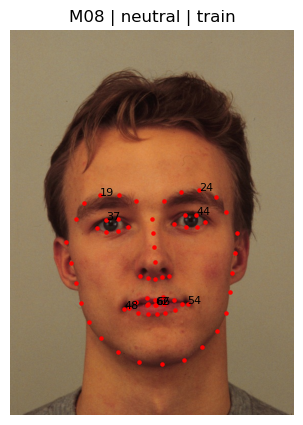

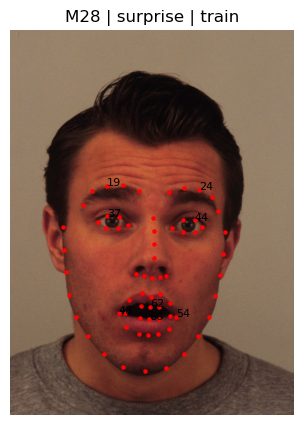

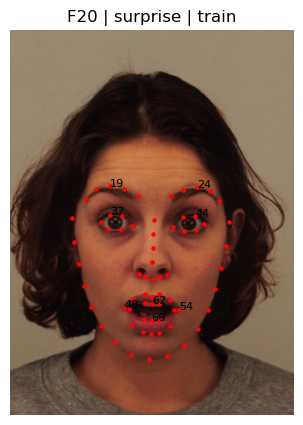

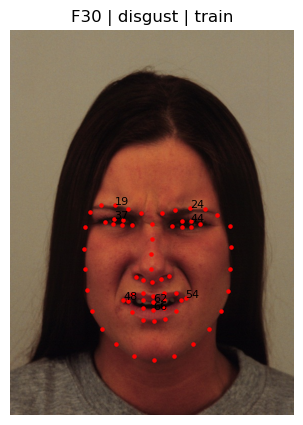

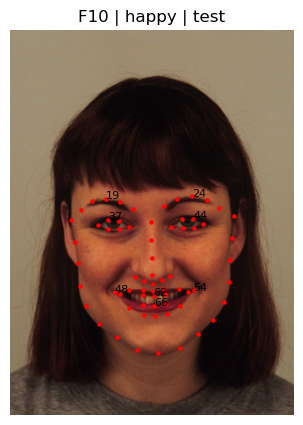

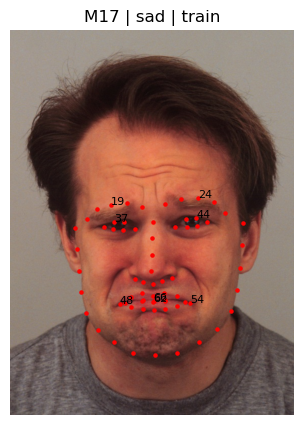

In [16]:
import matplotlib.pyplot as plt

for _, record in meta.sample(min(6, len(meta)), random_state=42).iterrows():
    try:
        image, points = detect_landmarks(record["path"])
        rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(5, 5))
        plt.imshow(rgb)
        plt.scatter(points[:, 0], points[:, 1], s=5, c="red")
        for index in (19, 24, 37, 44, 48, 54, 62, 66):
            plt.annotate(str(index), tuple(points[index]), fontsize=8)
        plt.title(
            f"{record['subject']} | {record['emotion']} | {record['split']}"
        )
        plt.axis("off")
        plt.show()
    except (ValueError, cv2.error) as exc:
        print(f"Failed: {record['path']} — {exc}")

## 7. Test feature calculation on one image

Run the geometric feature function on one photograph and check that all seven values are finite. This is the first step that actually tests the feature calculations.

In [ ]:
# TODO: Select one record from meta and call detect_landmarks().
# TODO: Calculate geometric_features(points) and inspect the seven values.

## 8. Extract geometric features for KDEF

Process the frontal photographs and build one DataFrame containing the image metadata, split label, and seven geometric features. Record unreadable images and landmark failures instead of silently dropping them.

In [ ]:
# TODO: Loop through meta, extract landmarks and calculate geometric features.
# TODO: Keep successful results in features_df and failures in a separate table.

## 9. Check the extracted dataset

Check missing values, feature ranges, class balance, and the number of successful images in each split. Review failed detections and check whether exclusions are concentrated in any emotion.

In [ ]:
# TODO: Summarize features_df and extraction failures.
# TODO: Inspect distributions and outliers without using the test set to choose features.

## 10. Save the feature table

Save the extracted features and a record of failed images so the slow landmark extraction does not need to be repeated for every experiment. Keep raw KDEF photographs outside Git.

In [ ]:
# TODO: Export features_df to DATA_OUT.
# TODO: Export extraction failures and record the feature definitions.

## 11. Prepare the fuzzy model inputs

Use the predefined training and test groups, encode the seven emotion labels consistently, and fit any scaling only on the training data. Keep the test group untouched until evaluation.

In [ ]:
# TODO: Build X_train, X_test, y_train, and y_test.
# TODO: Fit preprocessing on training data only and save the label order.

## 12. Check the PyFUME installation

Run a small smoke test to confirm the PyFUME API works in the dedicated Conda environment before training on KDEF. Record the API options that work with the installed version.

In [ ]:
# TODO: Import PyFUME and inspect its installed version and constructor.
# TODO: Fit a tiny training-only example before the full experiment.

## 13. Train the fuzzy classifier

Train the fuzzy approach selected for the seven emotion classes. If using one-versus-rest models, give each emotion its own target and preserve its generated rules and files.

In [ ]:
# TODO: Train one fuzzy model per emotion, or document another multiclass approach.
# TODO: Use only training subjects and keep each model output separate.

## 14. Predict emotions on the test subjects

Generate one predicted emotion for each test image. For a one-versus-rest approach, compare model outputs consistently and document how the final class is selected.

In [ ]:
# TODO: Generate model outputs for X_test.
# TODO: Convert model outputs to emotion labels using the documented decision rule.

## 15. Evaluate classification performance

Calculate accuracy, balanced accuracy, macro-F1, and a confusion matrix on the subject-independent KDEF test split. Report how many images were excluded because landmarks could not be extracted.

In [ ]:
# TODO: Calculate classification metrics and the confusion matrix.
# TODO: Save a small results table and the figure to OUT.

## 16. Inspect the fuzzy rules

Review a selection of the learned membership functions and rules, focusing on whether their facial measurements make sense for the associated expression. Distinguish interpretable rules from rules that merely fit the training data.

In [ ]:
# TODO: Read or export the rules preserved during training.
# TODO: Select representative rules and interpret their feature conditions.

## 17. Review errors and limitations

Identify the expressions most often confused and examine whether the errors relate to feature overlap, landmark quality, or unusual poses. Avoid drawing conclusions beyond the test results.

In [ ]:
# TODO: Summarize common confusions and any extraction failures.
# TODO: Compare the findings with the selected fuzzy rules.

## 18. Save models and experiment details

Save the trained models, preprocessing information, label order, feature definitions, and package versions needed to reproduce predictions. Check which outputs are appropriate for Git or the final submission.

In [ ]:
# TODO: Save the trained models and required preprocessing objects.
# TODO: Record the environment versions, paths convention, and experiment settings.

## 19. Notes for the report

Summarize the chosen geometric features, the fuzzy training method, test performance, examples of understandable rules, and main limitations. Include the required AI-use statement in the team report.

In [ ]:
# TODO: Collect the final metrics and figure locations.
# TODO: Write a brief evidence-based summary once the experiments are complete.